In [3]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# каталог с ноутбуками и корень проекта
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BACKEND = ROOT / "backend"
if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))
from src.analytics import assess, guess_mapping, normalize, read_table
from src.analytics.quality import drop_duplicates, trim_incomplete_tail
from src.analytics.schema import AMOUNT, CUSTOMER_ID, ORDER_DATE
# данные
DATA_PATH = ROOT / "data" / "raw" / "online_retail_II.xlsx"
raw = read_table(DATA_PATH)
source = "Online Retail II"

raw.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
# распознавание колонок
mapping = guess_mapping(raw)

for canonical, column in mapping.as_dict().items():
    print(f"{canonical:<12} <- {column}")

if mapping.unmapped:
    print("\nНе распознано:", ", ".join(map(str, mapping.unmapped)))

assert mapping.is_valid, f"Не хватает колонок: {mapping.missing_required}"

order_date   <- InvoiceDate
customer_id  <- Customer ID
order_id     <- Invoice
quantity     <- Quantity
unit_price   <- Price

Не распознано: StockCode, Description, Country


In [6]:
# отчистка 
clean = normalize(raw, mapping)
clean, duplicates = drop_duplicates(clean)
clean, tail_trimmed = trim_incomplete_tail(clean)
clean.head()

,order_date,customer_id,amount,order_id,quantity,unit_price
0,2009-12-01 07:45:00,13085,83.4,489434,12.0,6.95
1,2009-12-01 07:45:00,13085,81.0,489434,12.0,6.75
2,2009-12-01 07:45:00,13085,100.8,489434,48.0,2.10
3,2009-12-01 07:45:00,13085,30.0,489434,24.0,1.25
4,2009-12-01 07:45:00,13085,39.6,489434,24.0,1.65


In [7]:
frame = clean.copy()
frame["month"] = frame[ORDER_DATE].dt.to_period("M")

customers_total = frame[CUSTOMER_ID].nunique()
first_month = frame.groupby(CUSTOMER_ID)["month"].min()
frame["cohort"] = frame[CUSTOMER_ID].map(first_month)
frame["age"] = (frame["month"] - frame["cohort"]).apply(lambda delta: delta.n)

In [8]:
# Группируем данные и считаем уникальных клиентов для каждой когорты и возраста
cohort_data = frame.groupby(['cohort', 'age'])[CUSTOMER_ID].nunique().reset_index()
# Сводная таблица
cohort_pivot = cohort_data.pivot(index='cohort', columns='age', values=CUSTOMER_ID)

# Делим каждый столбец на самый первый (нулевой) столбец, где 100% пользователей
cohort_sizes = cohort_pivot.iloc[:,0]
retention = cohort_pivot.divide(cohort_sizes, axis=0)


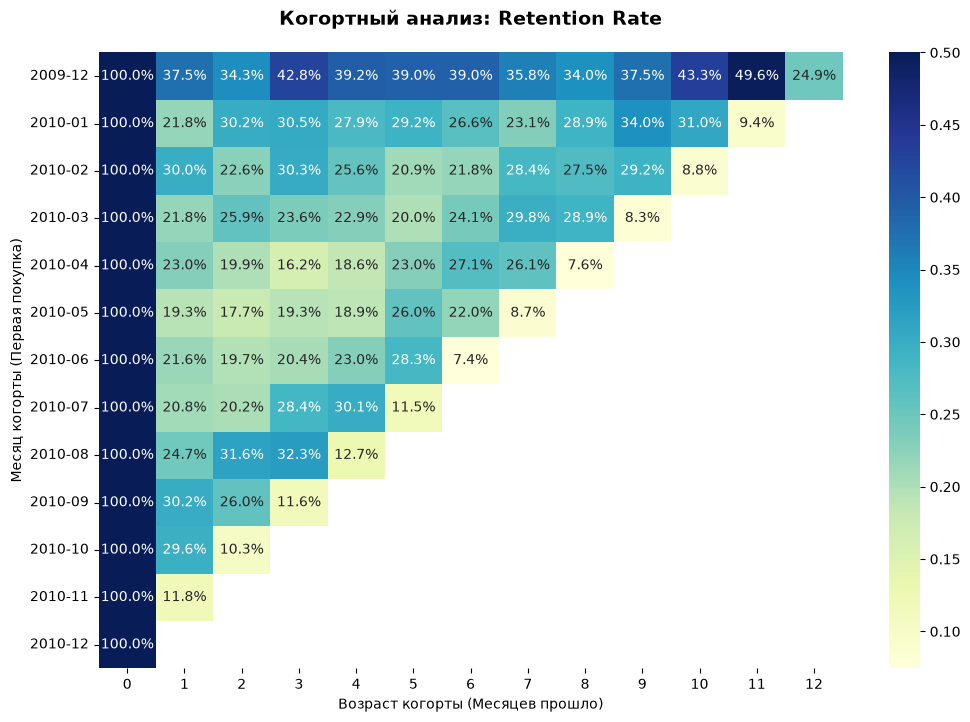

In [9]:
plt.figure(figsize=(12, 8))
plt.title('Когортный анализ: Retention Rate', fontsize=14, fontweight='bold', pad=20)

# Строим тепловую карту
sns.heatmap(
    retention, 
    annot=True,          
    fmt='.1%',           
    cmap='YlGnBu',       
    vmax=0.5,            
    cbar=True            
)

plt.ylabel('Месяц когорты (Первая покупка)')
plt.xlabel('Возраст когорты (Месяцев прошло)')
plt.show()

In [10]:
# Строим результирующую таблицу: Сегмент -> Люди, Деньги
segment_table = (
    frame.groupby("cohort")
    .agg(
        total_customers=("customer_id", "nunique"),  # Сколько людей
        total_revenue=("amount", "sum")             # Сколько денег
    )
    .rename(columns={
        "total_customers": "Количество людей",
        "total_revenue": "Всего денег"
    })
)

pd.options.display.float_format = '{:,.2f}'.format

# Выводим полную таблицу в консоль/ноутбук
print("--- ТАБЛИЦА СЕГМЕНТОВ ---")
print(segment_table)
print("\n" + "="*40 + "\n")

# 3. Находим ТОП-3 сегмента, которые приносят больше всего денег
top_3_segments = segment_table.sort_values(by="Всего денег", ascending=False).head(3)

print("--- ТОП-3 САМЫХ ПРИБЫЛЬНЫХ СЕГМЕНТА ---")
for i, (cohort, row) in enumerate(top_3_segments.iterrows(), 1):
    print(f"{i}. Сегмент {cohort}: {row['Всего денег']:,.2f} (людей в сегменте: {int(row['Количество людей'])} чел.)")

--- ТАБЛИЦА СЕГМЕНТОВ ---
         Количество людей  Всего денег
cohort                                
2009-12              1045 3,580,255.06
2010-01               394   515,696.17
2010-02               363   393,460.45
2010-03               436   432,898.78
2010-04               291   193,367.70
2010-05               254   162,230.44
2010-06               269   143,746.49
2010-07               183   104,255.29
2010-08               158    89,270.66
2010-09               242   159,019.13
2010-10               379   144,678.47
2010-11               322   108,471.93
2010-12                47     9,174.97


--- ТОП-3 САМЫХ ПРИБЫЛЬНЫХ СЕГМЕНТА ---
1. Сегмент 2009-12: 3,580,255.06 (людей в сегменте: 1045 чел.)
2. Сегмент 2010-01: 515,696.17 (людей в сегменте: 394 чел.)
3. Сегмент 2010-03: 432,898.78 (людей в сегменте: 436 чел.)


In [27]:
# выручка
frame['revenue'] = frame['quantity'] * frame['unit_price']
cohort_revenue = frame.groupby(['cohort', 'age'])['revenue'].sum().reset_index()
revenue_matrix = cohort_revenue.pivot(index='cohort', columns='age', values='revenue')

cohort_sizes_revenue = revenue_matrix.iloc[:,0]
revenue_retention = revenue_matrix.divide(cohort_sizes_revenue, axis =0)


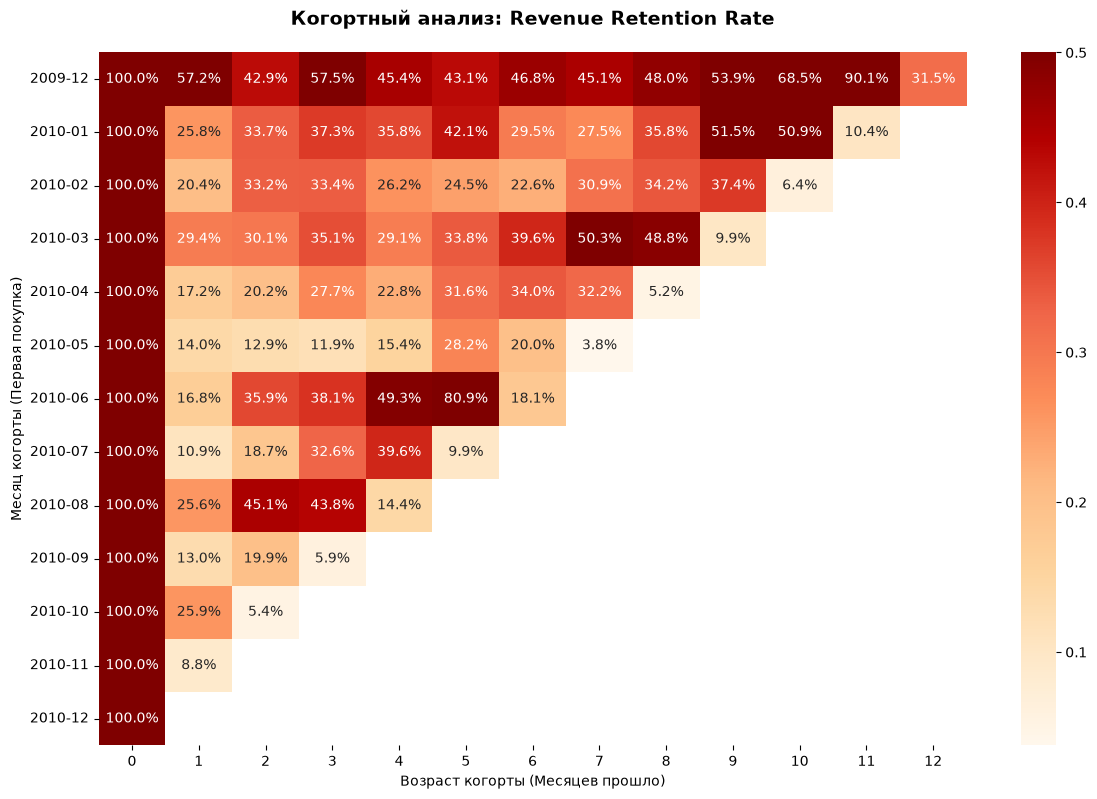

In [26]:
plt.figure(figsize=(14, 9))
plt.title('Когортный анализ: Revenue Retention Rate', fontsize=14, fontweight='bold', pad=20)

sns.heatmap(
    revenue_retention, 
    annot=True,          
    fmt='.1%',           
    cmap='OrRd',       
    vmax=0.5,            
    cbar=True            
)

plt.ylabel('Месяц когорты (Первая покупка)')
plt.xlabel('Возраст когорты (Месяцев прошло)')
plt.show()

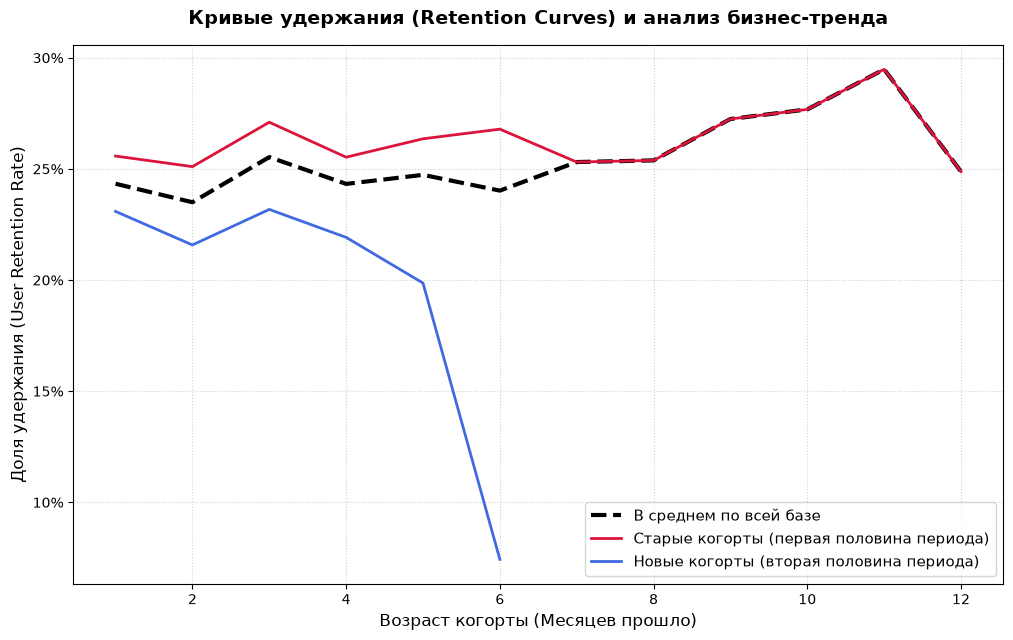

In [ ]:
plt.figure(figsize=(12, 7))

# Считаем среднюю кривую удержания по всей базе 
# (Исключаем 0-й месяц, так как там всегда 100%, чтобы график был более наглядным со 1-го месяца)
mean_retention = retention.mean(axis=0)
plt.plot(
    mean_retention.index[1:], 
    mean_retention.values[1:], 
    label='В среднем по всей базе', 
    color='black', 
    linewidth=3, 
    linestyle='--'
)

# Выделяем группы когорт для анализа тренда (Старые vs Новые)
# Разделим доступные когорты пополам
all_cohorts = retention.index.tolist()
half = len(all_cohorts) // 2
old_cohorts = all_cohorts[:half]
new_cohorts = all_cohorts[half:]

# Считаем среднее для старых и новых когорт отдельно
mean_old = retention.loc[old_cohorts].mean(axis=0)
mean_new = retention.loc[new_cohorts].mean(axis=0)

# Выводим их на график
plt.plot(mean_old.index[1:], mean_old.values[1:], label='Старые когорты (первая половина периода)', color='crimson', linewidth=2)
plt.plot(mean_new.index[1:], mean_new.values[1:], label='Новые когорты (вторая половина периода)', color='royalblue', linewidth=2)

plt.title('Кривые удержания (Retention Curves) и анализ бизнес-тренда', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Возраст когорты (Месяцев прошло)', fontsize=12)
plt.ylabel('Доля удержания (User Retention Rate)', fontsize=12)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.show()